<a href="https://colab.research.google.com/github/MH230145/proyecto-cmapss-nasa/blob/main/notebooks/pipeline_cmapss_fd001.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import joblib

# ==============================================================================
# 1. CONFIGURACIÓN DE ENTORNOS Y RUTAS PARA GOOGLE COLAB
# ==============================================================================
GITHUB_USER = "MH230145"
REPO_NAME = "proyecto-cmapss-nasa"
BRANCH = "main"

RAW_URL_BASE = f"https://raw.githubusercontent.com/{GITHUB_USER}/{REPO_NAME}/{BRANCH}/data/raw/"

# Carpetas dentro del entorno virtual de Google Colab
DATA_DIR = "data"
RAW_DATA_DIR = os.path.join(DATA_DIR, "raw")
PROCESSED_DATA_DIR = os.path.join(DATA_DIR, "processed")

os.makedirs(RAW_DATA_DIR, exist_ok=True)
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)

# Nombres de columnas según especificación NASA C-MAPSS
INDEX_NAMES = ['engine_id', 'cycle']
SETTING_NAMES = ['setting_1', 'setting_2', 'setting_3']
SENSOR_NAMES = [f'sensor_{i}' for i in range(1, 22)]
COL_NAMES = INDEX_NAMES + SETTING_NAMES + SENSOR_NAMES

EARLY_RUL_LIMIT = 125  # Piecewise RUL Limit (NASA Standard)

# ==============================================================================
# 2. FUNCIONES DE INGESTA Y PROCESAMIENTO (ETL)
# ==============================================================================
def load_dataset_colab(filename):
    """Descarga e ingesta los datos directamente desde GitHub en Google Colab."""
    url = RAW_URL_BASE + filename
    names = COL_NAMES if 'RUL' not in filename else ['RUL_actual']

    print(f" Descargando y leyendo {filename} en Google Colab...")
    df = pd.read_csv(url, sep=r'\s+', header=None, names=names)

    # Guarda una copia local en la carpeta data/raw del entorno Colab
    local_path = os.path.join(RAW_DATA_DIR, filename)
    df.to_csv(local_path, sep=" ", index=False, header=False)

    return df

def run_etl_pipeline_colab():
    print("="*60)
    print("   INICIANDO PIPELINE FASE 1: INGESTA Y ETL EN GOOGLE COLAB")
    print("="*60)

    # 1. Carga de los 3 conjuntos exigidos
    train_df = load_dataset_colab('train_FD001.txt')
    test_df = load_dataset_colab('test_FD001.txt')
    rul_test_df = load_dataset_colab('RUL_FD001.txt')

    # 2. Verificación explícita de nulos para auditoría de calidad de datos
    null_count = train_df.isnull().sum().sum() + test_df.isnull().sum().sum()

    # 3. Cálculo de RUL con Piecewise Clipping
    max_cycle = train_df.groupby('engine_id')['cycle'].transform('max')
    train_df['RUL'] = max_cycle - train_df['cycle']
    train_df['RUL_clipped'] = train_df['RUL'].clip(upper=EARLY_RUL_LIMIT)

    # 4. Filtrado de varianza (remueve sensores invariantes)
    sensor_std = train_df[SENSOR_NAMES].std()
    constant_sensors = sensor_std[sensor_std < 1e-4].index.tolist()
    drop_cols = constant_sensors + ['setting_3']
    feature_cols = [col for col in COL_NAMES if col not in INDEX_NAMES + drop_cols]

    # 5. Ajuste del Escalador sin Data Leakage (Fit SOLO en Train)
    scaler = StandardScaler()
    scaler.fit(train_df[feature_cols])

    # 6. Creación de Dataset Completo de Train (con engine_id y cycle para EDA / Fase 2)
    train_processed_df = train_df[INDEX_NAMES + ['RUL', 'RUL_clipped']].copy()
    scaled_features_train = pd.DataFrame(scaler.transform(train_df[feature_cols]), columns=feature_cols)
    train_processed_df = pd.concat([train_processed_df, scaled_features_train], axis=1)

    # 7. Separación de Matrices para Machine Learning (Fase 3)
    X_train = scaled_features_train
    y_train = train_df['RUL_clipped'].values

    # Para Test: tomamos el último ciclo disponible de cada motor
    test_last_cycle = test_df.groupby('engine_id').last().reset_index()
    X_test = pd.DataFrame(scaler.transform(test_last_cycle[feature_cols]), columns=feature_cols)
    y_test = rul_test_df['RUL_actual'].clip(upper=EARLY_RUL_LIMIT).values

    # 8. Almacenamiento local en Colab (CSV, Numpy arrays y Escalador Pkl)
    train_processed_df.to_csv(os.path.join(PROCESSED_DATA_DIR, "train_processed_df.csv"), index=False)
    X_train.to_csv(os.path.join(PROCESSED_DATA_DIR, "X_train.csv"), index=False)
    X_test.to_csv(os.path.join(PROCESSED_DATA_DIR, "X_test.csv"), index=False)
    np.save(os.path.join(PROCESSED_DATA_DIR, "y_train.npy"), y_train)
    np.save(os.path.join(PROCESSED_DATA_DIR, "y_test.npy"), y_test)

    scaler_path = os.path.join(PROCESSED_DATA_DIR, "scaler_fd001.pkl")
    joblib.dump(scaler, scaler_path)

    # 9. Resumen de ejecución
    print("\n" + "="*60)
    print("                ETL COMPLETADO EN GOOGLE COLAB")
    print("="*60)
    print(f" Registros de entrenamiento: {X_train.shape[0]} filas")
    print(f" Motores de prueba evaluados: {X_test.shape[0]} unidades")
    print(f" Valores nulos detectados: {null_count} (Dataset íntegro)")
    print(f" Columnas eliminadas por invarianza: {drop_cols}")
    print(f" Sensores/Predictores retenidos: {len(feature_cols)} características")
    print(f" Normalización (StandardScaler): Ajustado ÚNICAMENTE sobre Train")
    print(f" Escalador exportado a: {scaler_path}")
    print("="*60 + "\n")

    return train_processed_df, X_train, y_train, X_test, y_test, feature_cols

# ==============================================================================
# 3. EJECUCIÓN Y VISUALIZACIÓN INTERACTIVA EN COLAB
# ==============================================================================
train_processed_df, X_train, y_train, X_test, y_test, feature_cols = run_etl_pipeline_colab()

print("--- 1. PRIMERAS 5 FILAS DEL DATASET PROCESADO CON IDENTIFICADORES (Fase 2: EDA) ---")
display(train_processed_df.head())

print("\n--- 2. MATRIZ DE ENTRENAMIENTO PARA MACHINE LEARNING (Fase 3: ML) ---")
display(X_train.head())

   INICIANDO PIPELINE FASE 1: INGESTA Y ETL EN GOOGLE COLAB
 Descargando y leyendo train_FD001.txt en Google Colab...
 Descargando y leyendo test_FD001.txt en Google Colab...
 Descargando y leyendo RUL_FD001.txt en Google Colab...

                ETL COMPLETADO EN GOOGLE COLAB
 Registros de entrenamiento: 20631 filas
 Motores de prueba evaluados: 100 unidades
 Valores nulos detectados: 0 (Dataset íntegro)
 Columnas eliminadas por invarianza: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'setting_3']
 Sensores/Predictores retenidos: 17 características
 Normalización (StandardScaler): Ajustado ÚNICAMENTE sobre Train
 Escalador exportado a: data/processed/scaler_fd001.pkl

--- 1. PRIMERAS 5 FILAS DEL DATASET PROCESADO CON IDENTIFICADORES (Fase 2: EDA) ---


,engine_id,cycle,RUL,RUL_clipped,setting_1,setting_2,sensor_2,sensor_3,sensor_4,sensor_6,...,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,1,191,125,-0.315980,-1.372953,-1.721725,-0.134255,-0.925936,0.141683,...,-0.516338,-0.862813,-0.266467,0.334262,-1.058890,-0.269071,-0.603816,-0.781710,1.348493,1.194427
1,1,2,190,125,0.872722,-1.031720,-1.061780,0.211528,-0.643726,0.141683,...,-0.798093,-0.958818,-0.191583,1.174899,-0.363646,-0.642845,-0.275852,-0.781710,1.016528,1.236922
2,1,3,189,125,-1.961874,1.015677,-0.661813,-0.413166,-0.525953,0.141683,...,-0.234584,-0.557139,-1.015303,1.364721,-0.919841,-0.551629,-0.649144,-2.073094,0.739891,0.503423
3,1,4,188,125,0.324090,-0.008022,-0.661813,-1.261314,-0.784831,0.141683,...,0.188048,-0.713826,-1.539489,1.961302,-0.224597,-0.520176,-1.971665,-0.781710,0.352598,0.777792
4,1,5,187,125,-0.864611,-0.690488,-0.621816,-1.251528,-0.301518,0.141683,...,-0.516338,-0.457059,-0.977861,1.052871,-0.780793,-0.521748,-0.339845,-0.136018,0.463253,1.059552



--- 2. MATRIZ DE ENTRENAMIENTO PARA MACHINE LEARNING (Fase 3: ML) ---


,setting_1,setting_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,-0.315980,-1.372953,-1.721725,-0.134255,-0.925936,0.141683,1.121141,-0.516338,-0.862813,-0.266467,0.334262,-1.058890,-0.269071,-0.603816,-0.781710,1.348493,1.194427
1,0.872722,-1.031720,-1.061780,0.211528,-0.643726,0.141683,0.431930,-0.798093,-0.958818,-0.191583,1.174899,-0.363646,-0.642845,-0.275852,-0.781710,1.016528,1.236922
2,-1.961874,1.015677,-0.661813,-0.413166,-0.525953,0.141683,1.008155,-0.234584,-0.557139,-1.015303,1.364721,-0.919841,-0.551629,-0.649144,-2.073094,0.739891,0.503423
3,0.324090,-0.008022,-0.661813,-1.261314,-0.784831,0.141683,1.222827,0.188048,-0.713826,-1.539489,1.961302,-0.224597,-0.520176,-1.971665,-0.781710,0.352598,0.777792
4,-0.864611,-0.690488,-0.621816,-1.251528,-0.301518,0.141683,0.714393,-0.516338,-0.457059,-0.977861,1.052871,-0.780793,-0.521748,-0.339845,-0.136018,0.463253,1.059552


     FASE 2: ANÁLISIS EXPLORATORIO (EDA) Y RIGOR ESTADÍSTICO


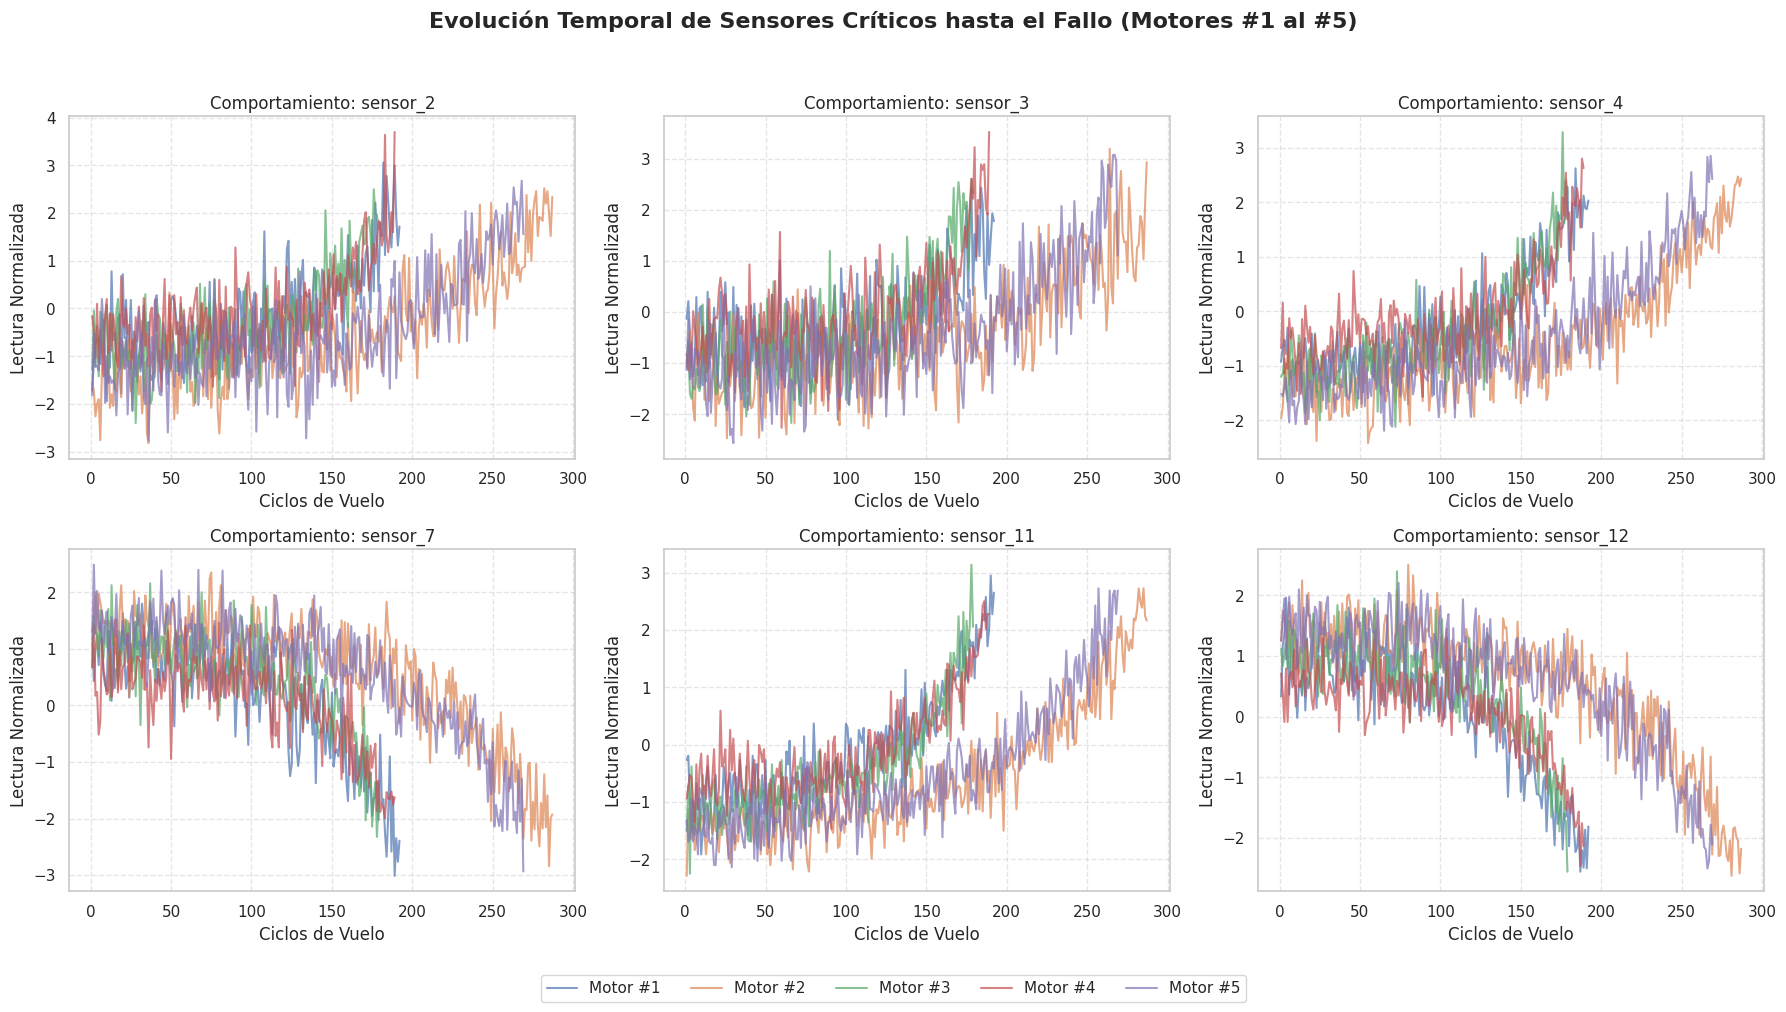

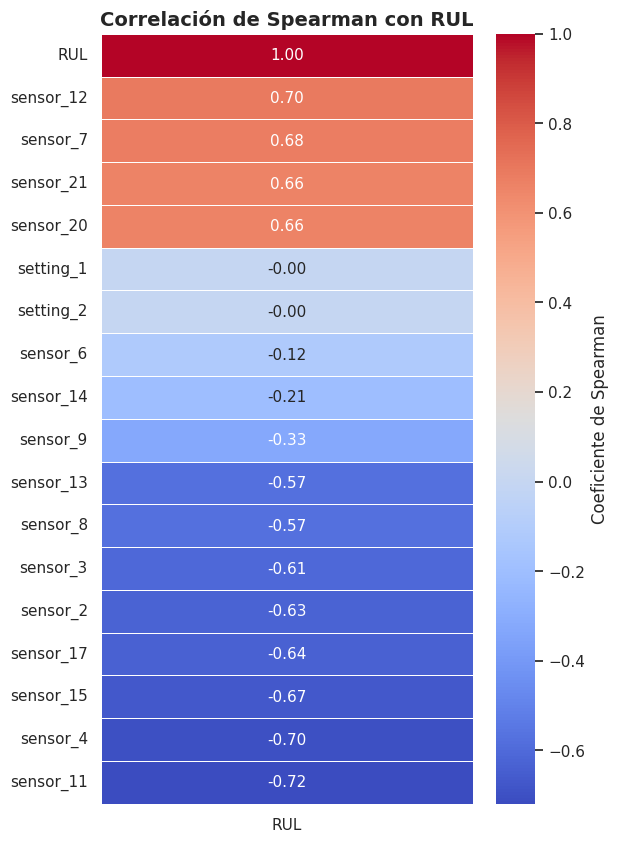


         RESULTADOS DE LAS PRUEBAS DE HIPÓTESIS ESTADÍSTICAS
Hipótesis Nula (H0): El sensor NO tiene relación con la degradación (RUL).
Hipótesis Alternativa (H1): El sensor SÍ muestra significancia estadística con la degradación (p < 0.05).



,Variable / Sensor,Coeficiente Spearman (r),p-value,Decisión Estadística
9,sensor_11,-0.7199,0.000000e+00,Rechazar H0 (Significativo)
4,sensor_4,-0.7045,0.000000e+00,Rechazar H0 (Significativo)
10,sensor_12,0.6954,0.000000e+00,Rechazar H0 (Significativo)
6,sensor_7,0.6824,0.000000e+00,Rechazar H0 (Significativo)
13,sensor_15,-0.6698,0.000000e+00,Rechazar H0 (Significativo)
16,sensor_21,0.6598,0.000000e+00,Rechazar H0 (Significativo)
15,sensor_20,0.6576,0.000000e+00,Rechazar H0 (Significativo)
14,sensor_17,-0.6353,0.000000e+00,Rechazar H0 (Significativo)
2,sensor_2,-0.6311,0.000000e+00,Rechazar H0 (Significativo)
3,sensor_3,-0.6087,0.000000e+00,Rechazar H0 (Significativo)


In [ ]:
  import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración de estilo visual profesional para reportes aeronáuticos
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

# ==============================================================================
# 1. ANÁLISIS DE DEGRADACIÓN TEMPORAL (Series de Tiempo por Motor)
# ==============================================================================
print("="*70)
print("     FASE 2: ANÁLISIS EXPLORATORIO (EDA) Y RIGOR ESTADÍSTICO")
print("="*70)

# Seleccionamos una muestra representativa de sensores críticos (temperaturas y presiones)
critical_sensors = ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_11', 'sensor_12']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Evolución Temporal de Sensores Críticos hasta el Fallo (Motores #1 al #5)", fontsize=16, fontweight='bold')

# Graficamos las trayectorias de degradación para los primeros 5 motores usando train_processed_df
for engine_id in range(1, 6):
    engine_data = train_processed_df[train_processed_df['engine_id'] == engine_id]
    for idx, sensor in enumerate(critical_sensors):
        ax = axes[idx // 3, idx % 3]
        ax.plot(engine_data['cycle'], engine_data[sensor], alpha=0.7, label=f'Motor #{engine_id}')
        ax.set_title(f'Comportamiento: {sensor}')
        ax.set_xlabel('Ciclos de Vuelo')
        ax.set_ylabel('Lectura Normalizada')
        ax.grid(True, linestyle='--', alpha=0.5)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


# ==============================================================================
# 2. MATRIZ DE CORRELACIÓN MULTIVARIABLE Y MAPA DE CALOR
# ==============================================================================
# Unimos las características de entrenamiento escaladas con la variable objetivo RUL
df_eda = X_train.copy()
df_eda['RUL'] = y_train

corr_matrix = df_eda.corr(method='spearman')

plt.figure(figsize=(6, 10))
sns.heatmap(corr_matrix[['RUL']].sort_values(by='RUL', ascending=False),
            annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Coeficiente de Spearman'})
plt.title("Correlación de Spearman con RUL", fontsize=14, fontweight='bold')
plt.show()


# ==============================================================================
# 3. PRUEBAS DE HIPÓTESIS ESTADÍSTICAS FORMALES (Significancia y p-values)
# ==============================================================================
print("\n" + "="*70)
print("         RESULTADOS DE LAS PRUEBAS DE HIPÓTESIS ESTADÍSTICAS")
print("="*70)
print("Hipótesis Nula (H0): El sensor NO tiene relación con la degradación (RUL).")
print("Hipótesis Alternativa (H1): El sensor SÍ muestra significancia estadística con la degradación (p < 0.05).\n")

hypothesis_results = []
eda_features = [col for col in X_train.columns]

for feature in eda_features:
    # Prueba de Correlación de Spearman
    coef, p_value = stats.spearmanr(df_eda[feature], df_eda['RUL'])
    is_significant = "Rechazar H0 (Significativo)" if p_value < 0.05 else "No Rechazar H0 (No Significativo)"

    hypothesis_results.append({
        'Variable / Sensor': feature,
        'Coeficiente Spearman (r)': round(coef, 4),
        'p-value': p_value,
        'Decisión Estadística': is_significant
    })

df_hypothesis = pd.DataFrame(hypothesis_results).sort_values(by='Coeficiente Spearman (r)', key=abs, ascending=False)

display(df_hypothesis)

     FASE 3: MODELADO ANALÍTICO Y MACHINE LEARNING (C-MAPSS FD001)
Entrenando Ridge Regression (Baseline)...
Entrenando Random Forest Regressor...
Entrenando XGBoost Regressor...

            TABLA COMPARATIVA DE DESEMPEÑO DE MODELOS


,Modelo ML,RMSE (Ciclos),MAE (Ciclos),R^2 Score,NASA Score
2,XGBoost Regressor,17.01,12.01,0.8199,890.55
1,Random Forest Regressor,17.04,11.97,0.8192,853.88
0,Ridge Regression (Baseline),20.59,16.37,0.7361,1229.15



---> Modelo Ganador Seleccionado: XGBoost Regressor
Modelo optimizado exportado exitosamente en: 'models/best_model_fd001.pkl'


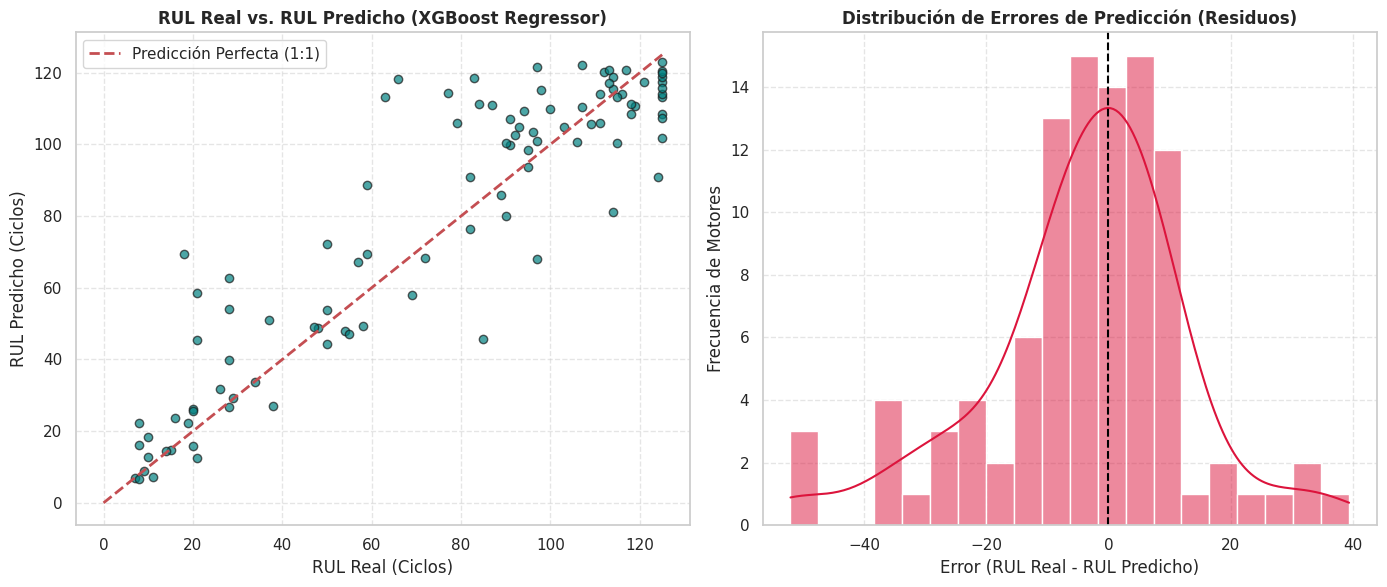

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ==============================================================================
# 1. FUNCIÓN DE EVALUACIÓN OFICIAL DE LA NASA (Métrica Asimétrica C-MAPSS)
# ==============================================================================
def score_cmapss(y_true, y_pred):
    """
    Calcula la función de pérdida asimétrica oficial de la NASA C-MAPSS.
    Penaliza con mayor severidad las sobreestimaciones de RUL (riesgo de falla en vuelo).
    """
    d = y_pred - y_true
    score = np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)
    return np.sum(score)

# ==============================================================================
# 2. ENTRENAMIENTO Y EVALUACIÓN DE MODELOS
# ==============================================================================
print("="*70)
print("     FASE 3: MODELADO ANALÍTICO Y MACHINE LEARNING (C-MAPSS FD001)")
print("="*70)

# Definimos los 3 modelos a comparar
models = {
    "Ridge Regression (Baseline)": Ridge(alpha=1.0),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    "XGBoost Regressor": XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42, n_jobs=-1)
}

results = []
trained_models = {}

# Bucle de entrenamiento y evaluación en Test (100 motores de prueba)
for name, model in models.items():
    print(f"Entrenando {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Aseguramos que la predicción no arroje valores negativos de RUL
    y_pred = np.clip(y_pred, a_min=0, a_max=125)

    # Cálculo de métricas requeridas por la rúbrica
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    nasa_score = score_cmapss(y_test, y_pred)

    results.append({
        'Modelo ML': name,
        'RMSE (Ciclos)': round(rmse, 2),
        'MAE (Ciclos)': round(mae, 2),
        'R^2 Score': round(r2, 4),
        'NASA Score': round(nasa_score, 2)
    })

    trained_models[name] = (model, y_pred)

# Presentación tabular de métricas de rendimiento
df_results = pd.DataFrame(results).sort_values(by='RMSE (Ciclos)', ascending=True)
print("\n" + "="*70)
print("            TABLA COMPARATIVA DE DESEMPEÑO DE MODELOS")
print("="*70)
display(df_results)


# ==============================================================================
# 3. SELECCIÓN DEL MEJOR MODELO Y EXPORTACIÓN PARA LA FASE 4 (DASHBOARD)
# ==============================================================================
best_model_name = df_results.iloc[0]['Modelo ML']
best_model, best_y_pred = trained_models[best_model_name]

print(f"\n---> Modelo Ganador Seleccionado: {best_model_name}")

# Guardamos el modelo en la carpeta models/ para que Streamlit lo consuma en la Fase 4
models_dir = os.path.join("models")
os.makedirs(models_dir, exist_ok=True)
best_model_path = os.path.join(models_dir, "best_model_fd001.pkl")
joblib.dump(best_model, best_model_path)
print(f"Modelo optimizado exportado exitosamente en: '{best_model_path}'")


# ==============================================================================
# 4. VISUALIZACIÓN GRÁFICA DE PREDICCIONES VS VALORES REALES (RUL TEST)
# ==============================================================================
plt.figure(figsize=(14, 6))

# Gráfico de dispersión y comparación lineal para los 100 motores de test
plt.subplot(1, 2, 1)
plt.scatter(y_test, best_y_pred, alpha=0.7, color='teal', edgecolors='k')
plt.plot([0, 125], [0, 125], 'r--', lw=2, label='Predicción Perfecta (1:1)')
plt.title(f'RUL Real vs. RUL Predicho ({best_model_name})', fontweight='bold')
plt.xlabel('RUL Real (Ciclos)')
plt.ylabel('RUL Predicho (Ciclos)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Gráfico de residuos (Errores de predicción)
residuos = y_test - best_y_pred
plt.subplot(1, 2, 2)
sns.histplot(residuos, kde=True, color='crimson', bins=20)
plt.axvline(0, color='black', linestyle='--', lw=1.5)
plt.title('Distribución de Errores de Predicción (Residuos)', fontweight='bold')
plt.xlabel('Error (RUL Real - RUL Predicho)')
plt.ylabel('Frecuencia de Motores')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
import os
import joblib
from google.colab import files

# 1. Crear directorios locales en la sesión de Colab
os.makedirs("models", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

# 2. Guardar Artefactos de la Fase 1 y Fase 3
print(" Exportando artefactos procesados...")

# Guardar DataFrame Procesado para EDA/Dashboard
train_processed_df.to_csv("data/processed/train_processed_df.csv", index=False)

# Guardar Escalador de StandardScaler
joblib.dump(scaler, "data/processed/scaler_fd001.pkl")

# Guardar el Modelo Ganador XGBoost
joblib.dump(best_model, "models/best_model_fd001.pkl")

print("Artefactos guardados con éxito en el disco de Colab.\n")

# 3. Descarga automática a tu computadora
print(" Iniciando descarga automática a tu equipo...")
files.download("models/best_model_fd001.pkl")
files.download("data/processed/scaler_fd001.pkl")
files.download("data/processed/train_processed_df.csv")

 Exportando artefactos procesados...
Artefactos guardados con éxito en el disco de Colab.

 Iniciando descarga automática a tu equipo...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>